# 07a. 구 통합 단기 가격 변화 예측 (재분석, ml-engineer)

## 질문
- **07-3(일부)·07 예측:** 25개 구를 한 모형으로 학습했을 때, 1분기 앞(h=1)과 4분기 앞(h=4)의 구별 구성 보정 가격 변화를 기준 예측(랜덤워크·확장 평균·모멘텀/풀링 AR(1))보다 잘 예측하는가?

## 방법과 지표
- **목표 변수:** 구별 구성 보정 지수(01번과 같은 사양: 월 더미 + 단지 고정효과 + 면적·층 구간, 연식 없음, `in_base_nobulk`)의 분기 평균 로그 `L`. 레이블 `y_h(t) = (L(t+h) − L(t)) × 100`(로그포인트).
- **특징(시점 t까지 관측 가능한 값):** 자기 구 과거 변화(1·2·4분기), 서울 전체 과거 변화(같은 시차), 상대 수준(구 ㎡당 중위가격 로그 − 서울), 거래량(로그, 직전 4분기 평균 대비 변화), 거래 구성(평균 연식, 연식 30년 이상 비중), 급지 `tier_k4`, 분기, 정책 사건(서울 공통, 종류별 개수).
- **주판정 모형(사전 고정):** Ridge(표준화). 알파 {0.1, 1, 10, 100}은 학습 자료 안의 분기 단위 내부 검증(레이블 종료 퍼지)으로 고르고, 조건 미달이면 사전 고정 알파 10.
- **탐색 모형:** RandomForest(500그루, `min_samples_leaf=5`), HistGradientBoosting(`max_iter=200`, `early_stopping=False`). 판정에 쓰지 않음.
- **기준선:** ① 랜덤워크(변화 0) ② 확장 평균(학습 구간 구별 평균 변화) ③ 모멘텀(같은 길이 직전 변화)과 풀링 AR(1).
- **지표:** MAE, RMSE(풀링), 국면별 MAE(예측 시점 2020~21 / 2022~23 / 2024~), 예측 시점별 구간 순위상관(Spearman) 평균, 학습 시간, 80% 예측 구간 포함률·pinball loss.
- **예측 기여도:** Ridge의 permutation importance(테스트 예측 풀링, 20회)와 요인군 제외 ΔMAE.

## 검증 설계
- **확장 윈도우 워크포워드.** 특징 시작 2019Q1, 첫 예측 시점 2020Q3, 마지막 예측 시점은 `t+h ≤ 2026Q2`. 레이블이 2026Q3(잠정 분기)에 걸리는 시점은 따로 보고.
- **퍼지:** 예측 시점 t의 학습에는 레이블 종료 분기 `s+h ≤ t`인 행만 씀.
- **최종 정제 자료 기반 의사 실시간 검증:** 예측 시점 t마다 t분기 말까지 **계약된** 거래만으로 구 지수를 다시 추정한 빈티지 V_t에서 특징과 학습 레이블을 계산. 평가 레이블은 01번 전체 표본 지수(`outputs/재검증/01/fig_gu_index_monthly.csv`, 최종 빈티지)로 고정해 모든 모형·기준선을 같은 값으로 채점.
  - 한계: 표본은 최종 `in_base_nobulk`이다. t 이후 취소된 거래는 당시 보였더라도 이미 빠져 있고, 일괄거래 판정(`bulk_n`)도 최종 취소 상태 기준이며, 신고 지연(당시 아직 신고되지 않은 거래)도 재현하지 못한다. 따라서 "당시 실제로 관측 가능했던 자료"로 한 검증이 아니다.
- 사후 비교(판정에 쓰지 않음): 특징·학습 레이블까지 최종 빈티지로 만든 결과.
- 금리 민감도(판정에 쓰지 않음): CD 금리 분기 평균 변화(시차 0·1·2)를 넣은 Ridge를 레이블 종료 2024Q2 이하 시점에서만 비교(금리 자료 마지막 완결 월 2024-07).

## 교재 장과 달라진 점
- **5장 다중선형회귀**(Ridge로 정규화), **3장 트리 계열**(RF·부스팅, 탐색), **1·2장 검증 흐름**(훈련/검증/테스트).
- 교재의 7:3 무작위 분할·10-fold 대신 확장 윈도우 워크포워드와 퍼지를 썼다. 구 패널은 시계열이라 무작위 분할은 미래 정보가 학습에 섞인다(조율안 1·3절).
- 교재 5장의 "미래 입력값 외삽" 대신, 시점 t까지 관측된 값만 특징으로 쓴다.
- 특징 중요도는 교재 3장의 트리 중요도 대신 permutation importance로 보고하고 "예측 기여도"로만 표시한다(조율안 3절).

**코드 수준:** 계수(크기)만 필요한 단계는 pandas 평균 빼기와 `LinearRegression`으로 쓴 쉬운 함수(`ru.easy_index`, `ru.easy_dong_level` 등)를 쓴다. 원래 함수와 값이 같다(차이 1e-8 이하). 표준오차·검정·부트스트랩이 필요한 단계는 기존 재검증 코드를 그대로 쓴다. 이 노트북에서 쉬운 버전으로 바꾼 곳: AR(1) 기준선(`LinearRegression`). 빈티지별 구 지수는 원래 함수를 쓴다(쉬운 버전과 값은 1e-12 수준으로 같지만, 랜덤포레스트가 이런 미세한 차이에도 분기가 달라져 결과가 바뀌기 때문).


In [1]:
import os
import sys
import time
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
import reanalysis_utils as ru

SEED = ru.SEED  # 42
OUT = ru.out_dir(ROOT, "07/07a")
plt = ru.set_korean_font()
T_NOTEBOOK = time.time()
pd.DataFrame({"package": ["python", "numpy", "pandas", "scipy", "scikit-learn", "statsmodels"],
              "version": [platform.python_version(), np.__version__, pd.__version__, scipy.__version__,
                          sklearn.__version__, statsmodels.__version__]})

,package,version
0,python,3.13.5
1,numpy,2.4.6
2,pandas,3.0.3
3,scipy,1.17.1
4,scikit-learn,1.9.0
5,statsmodels,0.15.0


## 1. 자료와 분기 단위 집계
- 표본: `in_base_nobulk`(2017-11~2026-09). 2017Q4는 부분 분기라 분기 단위 특징·레이블에 쓰지 않는다(지수 추정 기준월 2017-11은 01번과 같게 둔다).
- 분기 표기는 `YYYY-Qn` 문자열이다.

In [2]:
def qs(p):
    return f"{p.year}-Q{p.quarter}"


cols = ["gu", "complex_id", "contract_ym", "log_ppa", "ppa_manwon", "age", "area_bin", "floor_bin", "in_base_nobulk"]
tx = ru.load_tx(ROOT, columns=cols)
nob = tx[tx["in_base_nobulk"]].drop(columns="in_base_nobulk").reset_index(drop=True)
nob["q"] = pd.to_datetime(nob["contract_ym"], format="%Y-%m").dt.to_period("Q")
GUS = sorted(nob["gu"].unique())
MONTHS_ALL = ru.ym_range("2017-11", "2026-09")
Q_FIRST, Q_LAST = pd.Period("2018Q1", "Q"), pd.Period("2026Q3", "Q")
QUARTERS = pd.period_range(Q_FIRST, Q_LAST, freq="Q")
FEAT_START = pd.Period("2019Q1", "Q")
ORIGIN_FIRST = pd.Period("2020Q3", "Q")
EVAL_END = pd.Period("2026Q2", "Q")      # 주결과 레이블 종료 한도
HS = [1, 4]

# 분기 거래 통계(빈티지와 무관: 계약 분기 기준)
nq = nob[nob["q"] >= Q_FIRST]
gq = nq.groupby(["gu", "q"]).agg(n=("log_ppa", "size"), med_ppa=("ppa_manwon", "median"),
                                 mean_age=("age", "mean"),
                                 share_age30=("age", lambda a: float((a >= 30).mean()))).reset_index()
seoul_med = nq.groupby("q")["ppa_manwon"].median()
gu_groups = ru.read_csv_any(ROOT / "outputs/재검증/02/gu_groups.csv")
tier = gu_groups.set_index("gu")["tier_k4"].astype(int)
ev = ru.read_csv_any(ROOT / "outputs/재검증/06/table_event_calendar.csv")
ev["q"] = pd.to_datetime(ev["date"]).dt.to_period("Q")
pol = pd.DataFrame(index=QUARTERS)
pol["pol_any"] = [int((ev["q"] == q).any()) for q in QUARTERS]
for k, nm in [("정부 대책", "pol_gov"), ("규제지역 적용", "pol_reg"), ("토허제", "pol_lth")]:
    pol[nm] = [int(((ev["q"] == q) & (ev["kind"] == k)).sum()) for q in QUARTERS]
pd.DataFrame({"n_tx": [len(nob), len(nq)], "n_gu": [nob["gu"].nunique()] * 2,
              "period": ["2017-11~2026-09", "2018-01~2026-09"]}, index=["in_base_nobulk", "분기 집계(2018Q1~)"])

,n_tx,n_gu,period
in_base_nobulk,519370,25,2017-11~2026-09
분기 집계(2018Q1~),502730,25,2018-01~2026-09


위 표는 지수 추정 표본(첫 행)과 분기 단위 특징 계산 표본(둘째 행)의 거래 수다.

## 2. 구 지수 빈티지(V_t) 추정
예측 시점 t = 2020Q3~2026Q3 각각에 대해 t분기 말까지 계약된 거래만으로 25개 구 지수를 다시 추정한다(`ru.time_dummy_index`, `fe="complex_id"`, `CHAR_REFS_NOAGE`, `with_se=False`). 빈티지는 한 번 계산해 h=1·4에 같이 쓴다. V_2026Q3는 전체 표본이므로 01번 저장 지수와 같아야 한다(아래 점검).

In [3]:
def quarter_L(idx):
    """월별 log_index(gu, month) -> 분기 평균 L(wide: index=분기, columns=구)."""
    d = idx.copy()
    d["q"] = pd.to_datetime(d["month"], format="%Y-%m").dt.to_period("Q")
    d = d[d["q"] >= Q_FIRST]
    w = d.groupby(["q", "gu"])["log_index"].mean().unstack("gu")
    return w[GUS]


def vintage_index(t):
    end_m = (t.asfreq("M", how="end")).strftime("%Y-%m")
    months = ru.ym_range("2017-11", end_m)
    sub = nob[nob["contract_ym"] <= end_m]
    out = []
    for gu, d in sub.groupby("gu"):
        gi, _ = ru.time_dummy_index(d.reset_index(drop=True), months, fe="complex_id",
                                    char_refs=ru.CHAR_REFS_NOAGE, with_se=False)
        gi["gu"] = gu
        out.append(gi)
    idx = pd.concat(out, ignore_index=True)
    w = sub[sub["q"] >= Q_FIRST].groupby("gu").size().reindex(GUS).astype(float)
    return quarter_L(idx), w / w.sum()


t0 = time.time()
VINT = {}
for i, t in enumerate(pd.period_range(ORIGIN_FIRST, Q_LAST, freq="Q")):
    VINT[t] = vintage_index(t)
    if i % 6 == 5:
        print(f"빈티지 {i + 1}개 완료({qs(t)}), 누적 {time.time() - t0:.0f}초")
T_VINTAGE = time.time() - t0
final_idx = ru.read_csv_any(ROOT / "outputs/재검증/01/fig_gu_index_monthly.csv")
L_FINAL = quarter_L(final_idx)
w_final = nq.groupby("gu").size().reindex(GUS).astype(float)
W_FINAL = w_final / w_final.sum()
chk = float(np.nanmax(np.abs(VINT[Q_LAST][0].to_numpy() - L_FINAL.to_numpy())))
pd.DataFrame({"n_vintage": [len(VINT)], "vintage_sec": [round(T_VINTAGE, 1)],
              "max_abs_diff_V2026Q3_vs_01": [chk], "nan_in_final_L": [int(L_FINAL.isna().sum().sum())]})

빈티지 6개 완료(2021-Q4), 누적 3초


빈티지 12개 완료(2023-Q2), 누적 6초


빈티지 18개 완료(2024-Q4), 누적 11초


빈티지 24개 완료(2026-Q2), 누적 18초


,n_vintage,vintage_sec,max_abs_diff_V2026Q3_vs_01,nan_in_final_L
0,25,19.9,1.110223e-16,0


`max_abs_diff_V2026Q3_vs_01`이 0에 가까우면 빈티지 추정 코드가 01번 지수와 같은 사양이라는 뜻이다.

## 3. 특징·레이블 패널
한 빈티지의 분기 로그 지수 L(구×분기)과 그 빈티지의 구별 거래 가중치로 패널을 만든다. 과거 변화는 ×100(로그포인트)이다.

In [4]:
OWN = ["own_d1", "own_d2", "own_d4"]
SEO = ["seoul_d1", "seoul_d2", "seoul_d4"]
LEV = ["rel_level"]
VOL = ["log_n", "dlog_n_vs4"]
COMP = ["mean_age", "share_age30"]
TIER = [f"tier_{k}" for k in (1, 2, 3, 4)]
QTR = [f"qtr_{k}" for k in (1, 2, 3, 4)]
POL = ["pol_any", "pol_gov", "pol_reg", "pol_lth"]
FEATS = OWN + SEO + LEV + VOL + COMP + TIER + QTR + POL
GROUPS = {"과거 변화": OWN, "서울 공통": SEO, "수준": LEV, "거래량": VOL, "구성": COMP, "급지": TIER, "정책": POL}

gq_i = gq.set_index(["gu", "q"])
n_w = gq.pivot(index="q", columns="gu", values="n")[GUS]
lmed = np.log(gq.pivot(index="q", columns="gu", values="med_ppa")[GUS])


def build_panel(L, w):
    seoul = (L * w).sum(axis=1)
    rows = []
    for gu in GUS:
        Lg = L[gu]
        df = pd.DataFrame({"q": L.index, "gu": gu})
        for k in (1, 2, 4):
            df[f"own_d{k}"] = ((Lg - Lg.shift(k)) * 100).to_numpy()
            df[f"seoul_d{k}"] = ((seoul - seoul.shift(k)) * 100).to_numpy()
        for h in HS:
            df[f"y{h}"] = ((Lg.shift(-h) - Lg) * 100).to_numpy()
        df["rel_level"] = (lmed[gu] - np.log(seoul_med)).reindex(L.index).to_numpy()
        n = n_w[gu].reindex(L.index)
        df["log_n"] = np.log(n).to_numpy()
        prev4 = n.shift(1).rolling(4).mean()
        df["dlog_n_vs4"] = (np.log(n) - np.log(prev4)).to_numpy()
        sub = gq_i.loc[gu].reindex(L.index)
        df["mean_age"] = sub["mean_age"].to_numpy()
        df["share_age30"] = sub["share_age30"].to_numpy()
        for k in (1, 2, 3, 4):
            df[f"tier_{k}"] = float(tier[gu] == k)
            df[f"qtr_{k}"] = (L.index.quarter == k).astype(float)
        for c in POL:
            df[c] = pol[c].reindex(L.index).to_numpy().astype(float)
        rows.append(df)
    P = pd.concat(rows, ignore_index=True)
    return P[P["q"] >= FEAT_START].reset_index(drop=True)


PANEL = {t: build_panel(*VINT[t]) for t in VINT}
PANEL_FINAL = build_panel(L_FINAL, W_FINAL)
EVAL_Y = PANEL_FINAL.set_index(["gu", "q"])[[f"y{h}" for h in HS]]
pd.DataFrame({"n_rows_final_panel": [len(PANEL_FINAL)], "n_features": [len(FEATS)],
              "nan_features": [int(PANEL_FINAL[FEATS].isna().sum().sum())]})

,n_rows_final_panel,n_features,nan_features
0,775,23,0


특징 결측이 0이면 2019Q1 이후 모든 구×분기에서 특징이 계산되었다는 뜻이다.

## 4. 워크포워드 실행
각 h와 예측 시점 t에 대해 다음을 한다.
1. 학습 행: V_t 패널에서 `2019Q1 ≤ s`, `s+h ≤ t`.
2. Ridge 알파: 내부 검증 시점 v(`v+h ≤ t`)마다 `s'+h ≤ v`인 행으로 학습하고 v를 예측(V_t 레이블). 내부 학습 50행 이상인 v가 3개 이상이면 내부 MAE 최소 알파, 아니면 사전 고정 10.
3. Ridge·RF·HistGB·HistGB 분위(0.1/0.5/0.9)·기준선 예측, 평가 레이블은 최종 빈티지.
4. Ridge 잔차 구간: `t'+h ≤ t`인 과거 외부 예측 잔차(V_t 레이블 기준)가 20개 이상이면 그 10·90% 분위, 아니면 학습 구간 잔차.

In [5]:
ALPHAS = [0.1, 1.0, 10.0, 100.0]
ALPHA_DEFAULT = 10.0


def ridge(alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))


def choose_alpha(P, t, h, feats):
    vs = [v for v in sorted(P["q"].unique()) if v + h <= t]
    ok_vs, scores = [], {a: [] for a in ALPHAS}
    for v in vs:
        tr = P[(P["q"] + h <= v)]
        te = P[P["q"] == v]
        if len(tr) < 50 or len(te) == 0:
            continue
        ok_vs.append(v)
        for a in ALPHAS:
            m = ridge(a).fit(tr[feats], tr[f"y{h}"])
            scores[a].append(np.abs(m.predict(te[feats]) - te[f"y{h}"]).mean())
    if len(ok_vs) >= 3:
        best = min(ALPHAS, key=lambda a: np.mean(scores[a]))
        return best, "내부검증", len(ok_vs)
    return ALPHA_DEFAULT, "사전고정10(내부검증 조건 미달)", len(ok_vs)


def ar1_fit(tr, h):
    m = LinearRegression().fit(tr[[f"own_d{h}"]], tr[f"y{h}"])
    return np.array([m.intercept_, m.coef_[0]])   # [절편, 기울기]


def run_walkforward(panels, h, realtime=True, feats=FEATS, fixed_alpha=None, models=("ridge", "rf", "hgb", "q")):
    origins = [t for t in pd.period_range(ORIGIN_FIRST, Q_LAST, freq="Q") if (t + h <= Q_LAST) or t == Q_LAST]
    preds, folds, store = [], [], {}
    past = []  # (t', gu, pred)
    timing = {k: 0.0 for k in ["ridge", "rf", "hgb", "hgb_q"]}
    for t in origins:
        P = panels[t] if realtime else panels
        tr = P[(P["q"] + h <= t)].dropna(subset=feats + [f"y{h}"])
        te = P[P["q"] == t]
        if fixed_alpha is not None:
            alpha, rule, n_v = fixed_alpha[t], "주모형 알파 재사용", np.nan
        else:
            alpha, rule, n_v = choose_alpha(tr, t, h, feats)
        t0 = time.time()
        m = ridge(alpha).fit(tr[feats], tr[f"y{h}"])
        timing["ridge"] += time.time() - t0
        p_ridge = m.predict(te[feats])
        # 잔차 구간
        Pi = P.set_index(["gu", "q"])[f"y{h}"]
        res = [Pi.get((g, tp), np.nan) - pv for tp, g, pv in past if tp + h <= t]
        res = np.array([r for r in res if np.isfinite(r)])
        if len(res) >= 20:
            irule = f"과거 외부 잔차({len(res)}개)"
        else:
            res = tr[f"y{h}"].to_numpy() - m.predict(tr[feats])
            irule = f"학습 구간 잔차({len(res)}개)"
        q10, q90 = np.quantile(res, [0.1, 0.9])
        out = te[["gu", "q"]].copy()
        out["h"] = h
        out["ridge"] = p_ridge
        out["ridge_lo"], out["ridge_hi"] = p_ridge + q10, p_ridge + q90
        if "rf" in models:
            t0 = time.time()
            rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
            rf.fit(tr[feats], tr[f"y{h}"])
            timing["rf"] += time.time() - t0
            out["rf"] = rf.predict(te[feats])
        if "hgb" in models:
            t0 = time.time()
            hg = HistGradientBoostingRegressor(max_iter=200, early_stopping=False, random_state=SEED)
            hg.fit(tr[feats], tr[f"y{h}"])
            timing["hgb"] += time.time() - t0
            out["hgb"] = hg.predict(te[feats])
        if "q" in models:
            t0 = time.time()
            for qq, nm in [(0.1, "hgbq_lo"), (0.5, "hgbq_mid"), (0.9, "hgbq_hi")]:
                hq = HistGradientBoostingRegressor(loss="quantile", quantile=qq, max_iter=200,
                                                   early_stopping=False, random_state=SEED)
                hq.fit(tr[feats], tr[f"y{h}"])
                out[nm] = hq.predict(te[feats])
            timing["hgb_q"] += time.time() - t0
            # 분위 재배열(quantile rearrangement): 세 분위를 따로 학습하면 교차할 수 있으므로 예측마다 오름차순 정렬
            raw = out[["hgbq_lo", "hgbq_mid", "hgbq_hi"]].to_numpy()
            out["hgbq_rearranged"] = ~((raw[:, 0] <= raw[:, 1]) & (raw[:, 1] <= raw[:, 2]))
            out[["hgbq_lo", "hgbq_mid", "hgbq_hi"]] = np.sort(raw, axis=1)
        # 기준선
        out["rw"] = 0.0
        out["rw_lo"], out["rw_hi"] = np.quantile(tr[f"y{h}"], [0.1, 0.9])
        out["exp_mean"] = te["gu"].map(tr.groupby("gu")[f"y{h}"].mean()).to_numpy()
        out["momentum"] = te[f"own_d{h}"].to_numpy()
        b = ar1_fit(tr, h)
        out["ar1"] = b[0] + b[1] * te[f"own_d{h}"].to_numpy()
        out["y_eval"] = [EVAL_Y[f"y{h}"].get((g, t), np.nan) for g in te["gu"]]
        out["alpha"] = alpha
        preds.append(out)
        past += [(t, g, pv) for g, pv in zip(te["gu"], p_ridge)]
        lab_end = (tr["q"] + h).max()
        es = "최종예측" if t == Q_LAST else ("주결과" if t + h <= EVAL_END else "잠정")
        folds.append({"h": h, "test_origin": qs(t), "index_vintage_end": qs(t) if realtime else qs(Q_LAST),
                      "train_label_end_max": qs(lab_end), "n_train": len(tr), "alpha": alpha, "alpha_rule": rule,
                      "n_inner_valid_origin": n_v, "interval_rule": irule, "eval_set": es})
        store[t] = {"model": m, "X": te[feats].reset_index(drop=True), "tr": tr, "alpha": alpha}
    return pd.concat(preds, ignore_index=True), pd.DataFrame(folds), store, timing


t0 = time.time()
RES = {}
for h in HS:
    RES[h] = run_walkforward(PANEL, h, realtime=True)
    print(f"h={h} 실시간 워크포워드 {time.time() - t0:.0f}초")
fold_log = pd.concat([RES[h][1] for h in HS], ignore_index=True)
ru.save_chart_csv(fold_log, OUT, "fold_log.csv")
fold_log.groupby(["h", "eval_set", "alpha_rule"]).agg(n_origin=("test_origin", "size"), alpha_min=("alpha", "min"),
                                                      alpha_max=("alpha", "max")).reset_index()

h=1 실시간 워크포워드 89초


h=4 실시간 워크포워드 143초


,h,eval_set,alpha_rule,n_origin,alpha_min,alpha_max
0,1,잠정,내부검증,1,100.0,100.0
1,1,주결과,내부검증,23,1.0,100.0
2,1,최종예측,내부검증,1,100.0,100.0
3,4,잠정,내부검증,1,100.0,100.0
4,4,주결과,내부검증,15,0.1,100.0
5,4,주결과,사전고정10(내부검증 조건 미달),5,10.0,10.0
6,4,최종예측,내부검증,1,100.0,100.0


위 표는 h·평가 묶음별 예측 시점 수와 알파 선택 규칙 사용 횟수다. `fold_log.csv`에 시점별 `index_vintage_end`, `train_label_end_max`, 학습 행 수, 알파와 규칙이 있다.

In [6]:
fl = fold_log.copy()
pd.DataFrame({"purge_ok(train_label_end_max<=test_origin)": [bool((fl["train_label_end_max"] <= fl["test_origin"]).all())],
              "vintage_ok(index_vintage_end<=test_origin)": [bool((fl["index_vintage_end"] <= fl["test_origin"]).all())],
              "min_n_train": [int(fl["n_train"].min())], "max_n_train": [int(fl["n_train"].max())]})

,purge_ok(train_label_end_max<=test_origin),vintage_ok(index_vintage_end<=test_origin),min_n_train,max_n_train
0,True,True,75,750


## 5. 성능 지표와 사전 판정(A5)
- 주결과는 `t+h ≤ 2026Q2`인 예측 시점이다. 국면은 예측 시점 기준(2020~21 / 2022~23 / 2024~).
- ΔMAE = Ridge MAE − 가장 좋은 기준선 MAE. 95% 구간은 예측 시점(25개 구 묶음)을 블록으로 다시 뽑는 부트스트랩(B=999, SEED=42)이다.
- 기준선 ③은 모멘텀과 풀링 AR(1) 두 가지이고, 판정의 "가장 좋은 기준선"은 네 기준선(랜덤워크·확장 평균·모멘텀·AR(1)) 가운데 풀링 MAE가 가장 낮은 것으로 잡았다(보수적 해석).
- 참고로 h=4는 이웃 시점의 레이블이 3분기 겹치므로, 길이 h의 이동 블록 부트스트랩 구간도 함께 저장한다(판정에는 쓰지 않음).

In [7]:
MODELS = {"ridge": ("Ridge(주판정)", False, ""), "rf": ("RandomForest", False, "탐색"),
          "hgb": ("HistGB", False, "탐색"), "hgbq_mid": ("HistGB 분위 중앙값", False, "탐색"),
          "rw": ("랜덤워크", True, "기준선"), "exp_mean": ("확장 평균", True, "기준선"),
          "momentum": ("모멘텀", True, "기준선"), "ar1": ("풀링 AR(1)", True, "기준선")}
BASES = ["rw", "exp_mean", "momentum", "ar1"]
B = 999


def phase_of(q):
    y = q.year
    return "2020~21" if y <= 2021 else ("2022~23" if y <= 2023 else "2024~")


def boot_delta(df, a, b, block=1, seed=SEED):
    """예측 시점 블록 부트스트랩: 시점별 평균 절대오차 차이의 평균."""
    g = df.groupby("q")
    d = (g.apply(lambda x: np.abs(x[a] - x["y_eval"]).mean()) - g.apply(lambda x: np.abs(x[b] - x["y_eval"]).mean()))
    d = d.sort_index().to_numpy()
    rng = np.random.default_rng(seed)
    n = len(d)
    if block == 1:
        bs = np.array([d[rng.integers(0, n, n)].mean() for _ in range(B)])
    else:
        nb = int(np.ceil(n / block))
        bs = []
        for _ in range(B):
            st = rng.integers(0, n - block + 1, nb)
            bs.append(np.concatenate([d[s:s + block] for s in st])[:n].mean())
        bs = np.array(bs)
    return float(d.mean()), float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))


perf_rows, verdict = [], {}
for h in HS:
    pr = RES[h][0]
    pr["phase"] = pr["q"].map(phase_of)
    main = pr[(pr["q"] + h <= EVAL_END)].copy()
    prov = pr[(pr["q"] + h == Q_LAST)].copy()
    for set_name, df in [("주결과", main), ("잠정(레이블 2026Q3)", prov)]:
        for mk, (mname, bflag, _) in MODELS.items():
            e = df[mk] - df["y_eval"]
            phases = [("전체", df)] + ([(p, df[df["phase"] == p]) for p in ["2020~21", "2022~23", "2024~"]] if set_name == "주결과" else [])
            for ph, dd in phases:
                ee = dd[mk] - dd["y_eval"]
                perf_rows.append({"model": mname, "model_key": mk, "baseline_flag": bflag, "h": h, "phase": ph,
                                  "eval_set": set_name, "metric": "MAE", "value": float(np.abs(ee).mean()),
                                  "ci_low": np.nan, "ci_high": np.nan, "n_pred": len(dd), "n_origin": dd["q"].nunique()})
            perf_rows.append({"model": mname, "model_key": mk, "baseline_flag": bflag, "h": h, "phase": "전체",
                              "eval_set": set_name, "metric": "RMSE", "value": float(np.sqrt((e ** 2).mean())),
                              "ci_low": np.nan, "ci_high": np.nan, "n_pred": len(df), "n_origin": df["q"].nunique()})
            if mk != "rw" and set_name == "주결과":
                rho = df.groupby("q").apply(lambda x: stats.spearmanr(x[mk], x["y_eval"])[0])
                perf_rows.append({"model": mname, "model_key": mk, "baseline_flag": bflag, "h": h, "phase": "전체",
                                  "eval_set": set_name, "metric": "Spearman(시점별 평균)", "value": float(rho.mean()),
                                  "ci_low": float(rho.quantile(0.1)), "ci_high": float(rho.quantile(0.9)),
                                  "n_pred": len(df), "n_origin": df["q"].nunique()})
    # 판정
    mae = {k: np.abs(main[k] - main["y_eval"]).mean() for k in ["ridge"] + BASES}
    best = min(BASES, key=lambda k: mae[k])
    dm, lo, hi = boot_delta(main, "ridge", best)
    _, lo_b, hi_b = boot_delta(main, "ridge", best, block=h)
    ph_win = {p: bool(np.abs(main.loc[main.phase == p, "ridge"] - main.loc[main.phase == p, "y_eval"]).mean()
                      < np.abs(main.loc[main.phase == p, best] - main.loc[main.phase == p, "y_eval"]).mean())
              for p in ["2020~21", "2022~23", "2024~"]}
    c1, c2, c3 = mae["ridge"] < mae[best], hi < 0, sum(ph_win.values()) >= 2
    verdict[h] = {"h": h, "best_baseline": MODELS[best][0], "best_key": best, "mae_ridge": mae["ridge"],
                  "mae_best_baseline": mae[best], "delta_mae": dm, "ci_low": lo, "ci_high": hi,
                  "ci_low_moving_block": lo_b, "ci_high_moving_block": hi_b,
                  "phase_wins": sum(ph_win.values()), **{f"win_{p}": v for p, v in ph_win.items()},
                  "cond1": c1, "cond2": c2, "cond3": c3, "pass": bool(c1 and c2 and c3),
                  "n_pred": len(main), "n_origin": main["q"].nunique(),
                  "origin_first": qs(main["q"].min()), "origin_last": qs(main["q"].max())}
    perf_rows.append({"model": "Ridge − 최선 기준선", "model_key": "delta", "baseline_flag": False, "h": h, "phase": "전체",
                      "eval_set": "주결과", "metric": "ΔMAE", "value": dm, "ci_low": lo, "ci_high": hi,
                      "n_pred": len(main), "n_origin": main["q"].nunique()})
perf = pd.DataFrame(perf_rows)
VERD = pd.DataFrame(verdict.values())
VERD

,h,best_baseline,best_key,mae_ridge,mae_best_baseline,delta_mae,ci_low,ci_high,ci_low_moving_block,ci_high_moving_block,...,win_2022~23,win_2024~,cond1,cond2,cond3,pass,n_pred,n_origin,origin_first,origin_last
0,1,풀링 AR(1),ar1,3.718118,3.103832,0.614286,-0.541168,1.935010,-0.541168,1.935010,...,False,False,False,False,False,False,575,23,2020-Q3,2026-Q1
1,4,랜덤워크,rw,15.528004,10.205933,5.322071,0.307710,10.823362,1.188772,13.717834,...,False,True,False,False,False,False,500,20,2020-Q3,2025-Q2


위 표가 h별 사전 판정 결과다. `pass=True`일 때만 "기준선보다 나은 예측"으로 쓰고, 아니면 "기준선 대비 개선 확인되지 않음"으로 쓴다. `cond1`은 풀링 MAE, `cond2`는 ΔMAE 95% 구간 상한 < 0, `cond3`은 세 국면 중 둘 이상에서 MAE 우위다.

In [8]:
tab = perf[(perf.eval_set == "주결과") & (perf.phase == "전체") & perf.metric.isin(["MAE", "RMSE"])]
tab.pivot_table(index=["h", "model"], columns="metric", values="value").round(3)

metric              MAE    RMSE
h model                        
1 HistGB          3.594   4.597
  HistGB 분위 중앙값   3.044   4.133
  RandomForest    3.684   4.814
  Ridge(주판정)      3.718   5.139
  랜덤워크            3.519   4.522
  모멘텀             3.541   4.681
  풀링 AR(1)        3.104   4.335
  확장 평균           3.251   4.720
4 HistGB         14.738  18.516
  HistGB 분위 중앙값  12.846  17.120
  RandomForest   13.622  17.852
  Ridge(주판정)     15.528  20.028
  랜덤워크           10.206  12.201
  모멘텀            13.526  17.405
  풀링 AR(1)       14.758  20.483
  확장 평균          12.225  17.703

주결과 시점의 풀링 MAE·RMSE(로그포인트)다. 기준선과 모형이 같은 평가 레이블·같은 시점으로 채점되었다.

In [9]:
perf[(perf.eval_set == "주결과") & (perf.metric == "MAE") & (perf.phase != "전체")].pivot_table(
    index=["h", "model"], columns="phase", values="value").round(3)

phase            2020~21  2022~23   2024~
h model                                  
1 HistGB           3.169    4.917   2.701
  HistGB 분위 중앙값    2.746    4.613   1.849
  RandomForest     2.951    5.372   2.672
  Ridge(주판정)       3.573    4.720   2.925
  랜덤워크             3.973    3.995   2.794
  모멘텀              3.880    4.779   2.214
  풀링 AR(1)         3.216    4.462   1.822
  확장 평균            3.045    4.961   1.869
4 HistGB          16.804   18.510   7.644
  HistGB 분위 중앙값   16.897   15.479   5.283
  RandomForest    16.621   15.556   8.044
  Ridge(주판정)      16.845   21.441   6.327
  랜덤워크            12.217    8.680  10.229
  모멘텀             18.301   16.685   4.541
  풀링 AR(1)        17.519   19.609   5.528
  확장 평균           17.573   13.120   5.685

국면별 MAE다(국면은 예측 시점 기준).

In [10]:
perf[(perf.metric == "Spearman(시점별 평균)")].pivot_table(index="model", columns="h", values="value").round(3)

h,1,4
model,,
HistGB,0.251,-0.018
HistGB 분위 중앙값,0.328,0.057
RandomForest,0.308,-0.004
Ridge(주판정),0.252,0.102
모멘텀,0.119,0.212
풀링 AR(1),0.119,0.348
확장 평균,0.072,-0.161


예측 시점마다 25개 구의 예측값과 실제 변화의 순위상관을 구해 평균한 값이다. 서울 공통 충격을 빼고 "어느 구가 상대적으로 더 오를지"를 맞히는 정도를 본다.

## 6. 예측 구간
- `ridge_resid`: Ridge 점예측 + 잔차 10·90% 분위(주판정 모형에 연결).
- `hgb_quantile`: HistGB 분위 회귀(탐색).
- `rw_empirical`: 랜덤워크 + 학습 구간 변화의 경험 분위(비교 기준).

In [11]:
def pinball(y, p, q):
    d = y - p
    return float(np.mean(np.maximum(q * d, (q - 1) * d)))


int_rows = []
for h in HS:
    pr = RES[h][0]
    main = pr[(pr["q"] + h <= EVAL_END)]
    for mid, lo, hi, role in [("ridge_resid", "ridge_lo", "ridge_hi", "주판정"), ("hgb_quantile", "hgbq_lo", "hgbq_hi", "탐색"),
                              ("rw_empirical", "rw_lo", "rw_hi", "기준선")]:
        y = main["y_eval"]
        int_rows.append({"h": h, "model_id": mid, "role": role,
                         "coverage80": float(((y >= main[lo]) & (y <= main[hi])).mean()),
                         "pinball_q10": pinball(y, main[lo], 0.1), "pinball_q90": pinball(y, main[hi], 0.9),
                         "mean_width": float((main[hi] - main[lo]).mean()), "n_pred": len(main),
                         "n_rearranged": int(main["hgbq_rearranged"].sum()) if mid == "hgb_quantile" else 0})
    fin = pr[pr["q"] == Q_LAST]
    int_rows.append({"h": h, "model_id": "hgb_quantile", "role": "탐색(2026Q3 기준 최종 예측)", "coverage80": np.nan,
                     "pinball_q10": np.nan, "pinball_q90": np.nan, "mean_width": float((fin["hgbq_hi"] - fin["hgbq_lo"]).mean()),
                     "n_pred": len(fin), "n_rearranged": int(fin["hgbq_rearranged"].sum())})
INT = pd.DataFrame(int_rows)
ru.save_chart_csv(INT, OUT, "table_interval_eval.csv")
INT.round(3)

,h,model_id,role,coverage80,pinball_q10,pinball_q90,mean_width,n_pred,n_rearranged
0,1,ridge_resid,주판정,0.725,1.228,1.087,12.176,575,0
1,1,hgb_quantile,탐색,0.454,1.145,0.703,4.554,575,164
2,1,rw_empirical,기준선,0.807,1.121,0.633,10.440,575,0
3,1,hgb_quantile,탐색(2026Q3 기준 최종 예측),NaN,NaN,NaN,4.110,25,3
4,4,ridge_resid,주판정,0.500,6.717,2.210,27.238,500,0
5,4,hgb_quantile,탐색,0.250,8.509,1.801,7.529,500,177
6,4,rw_empirical,기준선,0.638,6.842,2.155,29.302,500,0
7,4,hgb_quantile,탐색(2026Q3 기준 최종 예측),NaN,NaN,NaN,15.003,25,11


80% 구간이면 포함률이 0.8에 가까워야 한다. pinball loss는 낮을수록 해당 분위 예측이 정확하다. `hgb_quantile`은 0.1·0.5·0.9 분위를 따로 학습해 서로 교차할 수 있으므로, 예측마다 세 값을 오름차순으로 다시 정렬(분위 재배열)해 lo80·중앙값·hi80으로 썼다. `n_rearranged`는 재배열이 일어난 예측 수다(마지막 행은 2026Q3 기준 최종 예측).

## 7. 예측 기여도(Ridge)
- **permutation importance:** 주결과 시점의 테스트 행을 모두 모아, 특징 하나(또는 원핫 묶음 하나)를 풀링된 테스트 행 사이에서 섞은 뒤 각 시점 모형으로 다시 예측해 MAE 증가를 잰다(20회, SEED=42).
- **요인군 제외 ΔMAE:** 해당 요인군을 빼고 같은 알파로 다시 학습했을 때 MAE 변화(양수 = 빼면 오차가 커짐).
- 둘 다 "예측 기여도"이며 가격에 대한 영향이나 효과가 아니다.

In [12]:
PERM_UNITS = {**{c: [c] for c in OWN + SEO + LEV + VOL + COMP}, "급지(tier_k4)": TIER, "분기": QTR, "정책": POL}
imp_rows, drop_rows = [], []
for h in HS:
    store = RES[h][2]
    ts = [t for t in store if t + h <= EVAL_END]
    Xs = pd.concat([store[t]["X"] for t in ts], ignore_index=True)
    owner = np.concatenate([[i] * len(store[t]["X"]) for i, t in enumerate(ts)])
    y = np.concatenate([[EVAL_Y[f"y{h}"].get((g, t), np.nan) for g in PANEL[t].loc[PANEL[t]["q"] == t, "gu"]] for t in ts])

    def predict_all(X):
        p = np.empty(len(X))
        for i, t in enumerate(ts):
            msk = owner == i
            p[msk] = store[t]["model"].predict(X.loc[msk, FEATS])
        return p

    base_mae = np.abs(predict_all(Xs) - y).mean()
    rng = np.random.default_rng(SEED)
    for unit, cs in PERM_UNITS.items():
        deltas = []
        for _ in range(20):
            Xp = Xs.copy()
            perm = rng.permutation(len(Xp))
            Xp[cs] = Xs[cs].to_numpy()[perm]
            deltas.append(np.abs(predict_all(Xp) - y).mean() - base_mae)
        imp_rows.append({"h": h, "feature": unit, "delta_mae_mean": float(np.mean(deltas)),
                         "delta_mae_std": float(np.std(deltas)), "base_mae": float(base_mae), "n_pred": len(y)})
    for gname, gcols in GROUPS.items():
        fs = [c for c in FEATS if c not in gcols]
        p = np.empty(len(y))
        for i, t in enumerate(ts):
            tr = store[t]["tr"]
            m = ridge(store[t]["alpha"]).fit(tr[fs], tr[f"y{h}"])
            p[owner == i] = m.predict(store[t]["X"][fs])
        drop_rows.append({"h": h, "group": gname, "delta_mae": float(np.abs(p - y).mean() - base_mae),
                          "base_mae": float(base_mae), "n_pred": len(y)})
IMP = pd.DataFrame(imp_rows)
DROP = pd.DataFrame(drop_rows)
ru.save_chart_csv(IMP, OUT, "fig_permutation_importance.csv")
ru.save_chart_csv(DROP, OUT, "fig_group_drop.csv")
IMP.pivot_table(index="feature", columns="h", values="delta_mae_mean").round(3).sort_values(1, ascending=False)

h,1,4
feature,,
dlog_n_vs4,0.449,-0.845
log_n,0.119,1.095
own_d2,0.110,0.706
급지(tier_k4),0.091,0.234
seoul_d2,0.075,0.388
mean_age,0.027,0.084
rel_level,0.019,-0.022
share_age30,0.012,0.076
seoul_d4,-0.016,-1.712


특징을 섞었을 때 Ridge 테스트 MAE가 늘어난 정도(로그포인트)다. 음수는 섞어도 오차가 줄었다는 뜻으로, 그 특징이 테스트 구간에서 예측에 보탬이 되지 않았음을 뜻한다.

In [13]:
DROP.pivot_table(index="group", columns="h", values="delta_mae").round(3)

h,1,4
group,,
거래량,0.129,3.197
과거 변화,-0.070,-0.404
구성,0.020,-0.192
급지,-0.012,-0.025
서울 공통,-0.156,-2.243
수준,-0.015,-0.142
정책,-0.542,-1.253


요인군 제외 ΔMAE다. 양수면 그 요인군을 넣었을 때 예측 오차가 그만큼 작았다는 뜻(예측 기여도)이다.

## 8. 사후 비교(최종 빈티지 특징)와 금리 민감도
둘 다 판정에 쓰지 않는다.
- 사후 비교: 특징·학습 레이블을 모두 최종 빈티지(01번 전체 표본 지수)로 만든 Ridge. 실시간 빈티지 결과와의 MAE 차이가 지수 수정(revision)이 예측 성능에 주는 차이다.
- 금리 민감도: CD 수익률 일별 고시금리의 분기 평균 변화(시차 0·1·2, %p). 레이블 종료 2024Q2 이하 예측 시점만, 같은 시점의 주모형 알파를 그대로 써서 금리 유무만 비교한다.

In [14]:
post_rows = []
for h in HS:
    pr_post, _, _, _ = run_walkforward(PANEL_FINAL, h, realtime=False, models=())
    m_rt = RES[h][0]
    a = m_rt[(m_rt["q"] + h <= EVAL_END)]
    b = pr_post[(pr_post["q"] + h <= EVAL_END)]
    for nm, df in [("실시간 빈티지", a), ("최종 빈티지(사후)", b)]:
        for mk in ["ridge", "momentum", "ar1", "exp_mean"]:
            post_rows.append({"h": h, "feature_vintage": nm, "model": MODELS[mk][0],
                              "mae": float(np.abs(df[mk] - df["y_eval"]).mean()), "n_pred": len(df)})
POST = pd.DataFrame(post_rows)
ru.save_chart_csv(POST, OUT, "table_vintage_posthoc.csv")
POST.pivot_table(index=["h", "model"], columns="feature_vintage", values="mae").round(3)

feature_vintage  실시간 빈티지  최종 빈티지(사후)
h model                             
1 Ridge(주판정)       3.718       3.583
  모멘텀              3.541       3.596
  풀링 AR(1)         3.104       3.145
  확장 평균            3.251       3.281
4 Ridge(주판정)      15.528      15.422
  모멘텀             13.526      13.876
  풀링 AR(1)        14.758      14.747
  확장 평균           12.225      12.314

In [15]:
rate = ru.read_csv_any(ROOT / "data/06_정책/한국주택금융공사_시장금리기본_20240820.csv")
cd = rate[rate["시장금리종류"] == "CD수익률"].copy()
cd["d"] = pd.to_datetime(cd["고시일자"])
cd = cd[cd["d"] <= "2024-07-31"]
cd_q = cd.groupby(cd["d"].dt.to_period("Q"))["고시금리"].mean()
dcd = cd_q.diff()
RATE_END = pd.Period("2024Q2", "Q")
RATE_F = ["rate_d0", "rate_d1", "rate_d2"]


def add_rate(P):
    P = P.copy()
    for k in (0, 1, 2):
        P[f"rate_d{k}"] = P["q"].map(lambda q: dcd.get(q - k, np.nan))
    return P


rate_rows = []
for h in HS:
    fl_h = fold_log[fold_log["h"] == h]
    alpha_map = {pd.Period(r.test_origin.replace("-", ""), "Q"): r.alpha for r in fl_h.itertuples()}
    origins = [t for t in pd.period_range(ORIGIN_FIRST, RATE_END, freq="Q") if t + h <= RATE_END]
    preds = []
    for t in origins:
        P = add_rate(PANEL[t])
        tr = P[(P["q"] + h <= t)]
        te = P[P["q"] == t]
        y = np.array([EVAL_Y[f"y{h}"].get((g, t), np.nan) for g in te["gu"]])
        for nm, fs in [("주모형(금리 없음)", FEATS), ("금리 포함", FEATS + RATE_F)]:
            m = ridge(alpha_map[t]).fit(tr[fs], tr[f"y{h}"])
            preds.append(pd.DataFrame({"q": t, "gu": te["gu"].to_numpy(), "spec": nm, "pred": m.predict(te[fs]), "y_eval": y}))
    pp = pd.concat(preds)
    wide = pp.pivot_table(index=["q", "gu"], columns="spec", values=["pred"]).droplevel(0, axis=1)
    wide["y_eval"] = pp.drop_duplicates(["q", "gu"]).set_index(["q", "gu"])["y_eval"]
    wide = wide.reset_index()
    dm, lo, hi = boot_delta(wide, "금리 포함", "주모형(금리 없음)")
    for nm in ["주모형(금리 없음)", "금리 포함"]:
        rate_rows.append({"h": h, "spec": nm, "mae": float(np.abs(wide[nm] - wide["y_eval"]).mean()),
                          "delta_mae_rate_minus_base": dm if nm == "금리 포함" else np.nan,
                          "ci_low": lo if nm == "금리 포함" else np.nan, "ci_high": hi if nm == "금리 포함" else np.nan,
                          "n_pred": len(wide), "origin_first": qs(min(origins)), "origin_last": qs(max(origins))})
RATE = pd.DataFrame(rate_rows)
ru.save_chart_csv(RATE, OUT, "table_rate_sensitivity.csv")
RATE.round(3)

,h,spec,mae,delta_mae_rate_minus_base,ci_low,ci_high,n_pred,origin_first,origin_last
0,1,주모형(금리 없음),4.013,NaN,NaN,NaN,375,2020-Q3,2024-Q1
1,1,금리 포함,4.789,0.775,-0.654,2.91,375,2020-Q3,2024-Q1
2,4,주모형(금리 없음),19.295,NaN,NaN,NaN,300,2020-Q3,2023-Q2
3,4,금리 포함,16.455,-2.840,-8.594,3.41,300,2020-Q3,2023-Q2


금리 포함 Ridge와 주모형의 MAE 차이(음수 = 금리를 넣으면 오차가 줄어듦)와 예측 시점 블록 부트스트랩 95% 구간이다. 금리는 시장 상황에 반응해 움직이는 내생 변수이므로, 이 비교는 예측 기여도이지 금리의 영향이 아니다.

## 9. 2026Q3(잠정) 기준 구별 예측값
- V_2026Q3(= 전체 표본)로 학습한 Ridge 점예측과 잔차 구간(`ridge_resid`), HistGB 분위 회귀(`hgb_quantile`, 탐색).
- 2026Q3는 잠정 분기(2026-08~09 잠정 월 포함)이고, 학습 레이블 일부도 2026Q3에 걸린다.
- 보고서에는 `ridge_resid`가 A5를 통과한 h의 값만 제시한다.

In [16]:
fc_rows = []
for h in HS:
    pr = RES[h][0]
    last = pr[pr["q"] == Q_LAST]
    for r in last.itertuples():
        fc_rows.append({"gu": r.gu, "h": h, "target_quarter": qs(Q_LAST + h), "model_id": "ridge_resid",
                        "point": r.ridge, "lo80": r.ridge_lo, "hi80": r.ridge_hi,
                        "beats_baseline": bool(verdict[h]["pass"]), "role": "주판정"})
        fc_rows.append({"gu": r.gu, "h": h, "target_quarter": qs(Q_LAST + h), "model_id": "hgb_quantile",
                        "point": r.hgbq_mid, "lo80": r.hgbq_lo, "hi80": r.hgbq_hi,
                        "beats_baseline": pd.NA, "role": "탐색"})
FC = pd.DataFrame(fc_rows)
ru.save_chart_csv(FC, OUT, "fig_gu_forecast.csv")
FC.groupby(["h", "model_id"])[["point", "lo80", "hi80"]].agg(["min", "median", "max"]).round(2)

point                 lo80                hi80              
                  min median    max    min median    max   min median    max
h model_id                                                                  
1 hgb_quantile  -2.15   1.41   5.13  -5.10  -0.51   1.61  1.87   2.75   6.52
  ridge_resid   -1.90   0.20   2.14  -9.02  -6.92  -4.98  3.56   5.66   7.60
4 hgb_quantile -10.27  -2.34  20.81 -10.78  -7.58  13.01  3.34  11.06  26.40
  ridge_resid   -5.92   2.56   9.28 -40.51 -32.03 -25.32 -0.79   7.69  14.41

구별 예측값의 분포(최소·중앙·최대, 로그포인트)만 요약했다. 구별 값은 `fig_gu_forecast.csv`에 있다. 이 값은 가정 없는 미래 확정치가 아니라 모형 계산값이며, 매수·매도 판단 근거가 아니다.

## 10. 차트와 저장

In [17]:
pred_long = []
for h in HS:
    pr = RES[h][0]
    pr = pr[pr["q"] < Q_LAST]
    for mk in ["ridge", "rf", "hgb", "rw", "exp_mean", "momentum", "ar1"]:
        pred_long.append(pd.DataFrame({"h": h, "test_origin": pr["q"].map(qs), "gu": pr["gu"], "model": MODELS[mk][0],
                                       "pred": pr[mk].round(4), "actual": pr["y_eval"].round(4),
                                       "eval_set": np.where(pr["q"] + h <= EVAL_END, "주결과", "잠정")}))
PRED = pd.concat(pred_long, ignore_index=True)
ridge_pred = PRED[PRED.model == "Ridge(주판정)"]
ru.save_chart_csv(ridge_pred, OUT, "fig_pred_vs_actual.csv")
pf = perf[["model", "baseline_flag", "h", "phase", "eval_set", "metric", "value", "ci_low", "ci_high", "n_pred", "n_origin"]].copy()
pf["note"] = pf["model"].map({v[0]: v[2] for v in MODELS.values()}).fillna("")
pf["split_type"] = "워크포워드"
ru.save_chart_csv(pf, OUT, "table_model_performance.csv")
ru.save_chart_csv(VERD, OUT, "table_verdict.csv")
mae_main = perf[(perf.eval_set == "주결과") & (perf.metric == "MAE")]
ru.save_chart_csv(mae_main[["model", "baseline_flag", "h", "phase", "value", "n_pred"]].rename(columns={"value": "mae"}),
                  OUT, "fig_mae_comparison.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, h in zip(axes, HS):
    d = ridge_pred[(ridge_pred.h == h) & (ridge_pred.eval_set == "주결과")]
    ax.scatter(d["pred"], d["actual"], s=8, alpha=0.4, color="tab:blue")
    lim = [min(d["pred"].min(), d["actual"].min()), max(d["pred"].max(), d["actual"].max())]
    ax.plot(lim, lim, color="gray", lw=1, ls="--")
    ax.axhline(0, color="lightgray", lw=0.8)
    ax.set_xlabel("Ridge 예측 변화 (로그포인트)")
    ax.set_ylabel("실제 변화 (로그포인트, 최종 빈티지)")
    ax.set_title(f"구별 {h}분기 앞 예측 vs 실제 (h={h})")
fig.text(0.01, -0.02, f"n=h1 {int(VERD.loc[0, 'n_pred'])}건·h4 {int(VERD.loc[1, 'n_pred'])}건(25개 구 × 예측 시점), "
         "예측 시점 2020Q3~, 의사 실시간 빈티지. 자료: outputs/재검증/07/07a/fig_pred_vs_actual.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_pred_vs_actual.png")
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
order = ["Ridge(주판정)", "RandomForest", "HistGB", "랜덤워크", "확장 평균", "모멘텀", "풀링 AR(1)"]
for ax, h in zip(axes, HS):
    d = mae_main[(mae_main.h == h) & (mae_main.phase == "전체")].set_index("model").reindex(order)
    colors = ["tab:blue", "tab:cyan", "tab:cyan", "gray", "gray", "gray", "gray"]
    ax.barh(order[::-1], d["value"].to_numpy()[::-1], color=colors[::-1])
    for i, v in enumerate(d["value"].to_numpy()[::-1]):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
    ax.set_xlabel("MAE (로그포인트)")
    ax.set_title(f"모형·기준선 MAE (h={h}, 주결과 시점)")
fig.text(0.01, -0.02, "파랑=주판정 Ridge, 하늘=탐색 모형, 회색=기준선. 자료: outputs/재검증/07/07a/fig_mae_comparison.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_mae_comparison.png")
plt.close(fig)
pd.DataFrame({"file": sorted(p.name for p in OUT.iterdir())})

,file
0,fig_group_drop.csv
1,fig_gu_forecast.csv
2,fig_mae_comparison.csv
3,fig_mae_comparison.png
4,fig_permutation_importance.csv
5,fig_pred_vs_actual.csv
6,fig_pred_vs_actual.png
7,fold_log.csv
8,meta.json
9,summary.csv


## 11. summary.csv와 meta.json

In [18]:
def ym_of(q, end=False):
    return (q.asfreq("M", how="end" if end else "start")).strftime("%Y-%m")


rows = []


def add(key, label, value, unit, n, ps, pe, split, claim, src, note):
    rows.append({"key": key, "label": label, "value": value, "unit": unit, "sample_n": int(n),
                 "period": f"{ps}~{pe}", "period_start": ps, "period_end": pe, "split_type": split,
                 "claim_level": claim, "source_file": src, "note": note})


for h in HS:
    v = verdict[h]
    o1 = pd.Period(v["origin_first"].replace("-", ""), "Q")
    o2 = pd.Period(v["origin_last"].replace("-", ""), "Q")
    ps, pe = ym_of(o1), ym_of(o2 + h, end=True)
    base_note = f"예측 시점 {v['origin_first']}~{v['origin_last']}({v['n_origin']}개) × 25개 구, 최종 정제 자료 기반 의사 실시간 검증, 퍼지 s+h≤t"
    add(f"a_h{h}_verdict_pass", f"h={h} 사전 판정 통과 여부(1=기준선보다 나은 예측, 0=개선 확인되지 않음)", int(v["pass"]), "0/1",
        v["n_pred"], ps, pe, "워크포워드", "예측 기여도", "table_verdict.csv",
        f"주판정 Ridge. 조건1 {v['cond1']}, 조건2 {v['cond2']}, 조건3 {v['cond3']}(국면 우위 {v['phase_wins']}/3). {base_note}")
    add(f"a_h{h}_mae_ridge", f"h={h} Ridge 풀링 MAE", round(v["mae_ridge"], 6), "로그포인트", v["n_pred"], ps, pe, "워크포워드",
        "예측 기여도", "table_model_performance.csv", base_note)
    add(f"a_h{h}_mae_best_baseline", f"h={h} 최선 기준선({v['best_baseline']}) 풀링 MAE", round(v["mae_best_baseline"], 6),
        "로그포인트", v["n_pred"], ps, pe, "워크포워드", "예측 기여도", "table_model_performance.csv",
        f"기준선 4개(랜덤워크·확장 평균·모멘텀·풀링 AR(1)) 중 최저. {base_note}")
    add(f"a_h{h}_delta_mae", f"h={h} Ridge − 최선 기준선 ΔMAE", round(v["delta_mae"], 6), "로그포인트", v["n_pred"], ps, pe,
        "워크포워드", "예측 기여도", "table_verdict.csv",
        f"95% CI {v['ci_low']:.3f}~{v['ci_high']:.3f}(예측 시점 블록 부트스트랩 B=999, SEED=42). 참고: 길이 {h} 이동 블록 CI "
        f"{v['ci_low_moving_block']:.3f}~{v['ci_high_moving_block']:.3f}")
    for mk in ["rw", "exp_mean", "momentum", "ar1"]:
        val = perf[(perf.model_key == mk) & (perf.h == h) & (perf.eval_set == "주결과") & (perf.metric == "MAE") & (perf.phase == "전체")]["value"].iloc[0]
        add(f"a_h{h}_mae_{mk}", f"h={h} 기준선 {MODELS[mk][0]} 풀링 MAE", round(val, 6), "로그포인트", v["n_pred"], ps, pe,
            "워크포워드", "예측 기여도", "table_model_performance.csv", f"기준선. {base_note}")
    for mk in ["rf", "hgb"]:
        val = perf[(perf.model_key == mk) & (perf.h == h) & (perf.eval_set == "주결과") & (perf.metric == "MAE") & (perf.phase == "전체")]["value"].iloc[0]
        add(f"a_h{h}_mae_{mk}", f"h={h} {MODELS[mk][0]} 풀링 MAE", round(val, 6), "로그포인트", v["n_pred"], ps, pe,
            "워크포워드", "예측 기여도", "table_model_performance.csv", f"탐색 모형(판정에 쓰지 않음). {base_note}")
    rho = perf[(perf.model_key == "ridge") & (perf.h == h) & (perf.metric == "Spearman(시점별 평균)")].iloc[0]
    add(f"a_h{h}_spearman_ridge", f"h={h} Ridge 구간 순위상관(시점별 평균)", round(rho["value"], 6), "상관계수", v["n_pred"], ps, pe,
        "워크포워드", "예측 기여도", "table_model_performance.csv",
        f"시점별 Spearman 10~90% 분위 {rho['ci_low']:.3f}~{rho['ci_high']:.3f}. {base_note}")
    iv = INT[(INT.h == h) & (INT.model_id == "ridge_resid")].iloc[0]
    add(f"a_h{h}_coverage80_ridge_resid", f"h={h} Ridge 잔차 80% 구간 포함률", round(iv["coverage80"], 6), "비율", v["n_pred"], ps, pe,
        "워크포워드", "예측 기여도", "table_interval_eval.csv", f"목표 0.8. 평균 폭 {iv['mean_width']:.2f} 로그포인트")
    ivq = INT[(INT.h == h) & (INT.model_id == "hgb_quantile") & (INT.role == "탐색")].iloc[0]
    ivf = INT[(INT.h == h) & (INT.model_id == "hgb_quantile") & (INT.role != "탐색")].iloc[0]
    add(f"a_h{h}_coverage80_hgb_quantile", f"h={h} HistGB 분위 80% 구간 포함률", round(ivq["coverage80"], 6), "비율", v["n_pred"], ps, pe,
        "워크포워드", "예측 기여도", "table_interval_eval.csv",
        f"탐색 모형. 평균 폭 {ivq['mean_width']:.2f} 로그포인트. 분위 재배열(예측마다 세 분위 오름차순 정렬) 적용: 평가 {int(ivq['n_rearranged'])}/{int(ivq['n_pred'])}건, "
        f"2026Q3 최종 예측 {int(ivf['n_rearranged'])}/{int(ivf['n_pred'])}건 재배열")
    top = IMP[IMP.h == h].sort_values("delta_mae_mean", ascending=False).iloc[0]
    add(f"a_h{h}_perm_top", f"h={h} Ridge permutation importance 1위({top['feature']}) ΔMAE", round(top["delta_mae_mean"], 6),
        "로그포인트", v["n_pred"], ps, pe, "워크포워드", "예측 기여도", "fig_permutation_importance.csv",
        f"20회 표준편차 {top['delta_mae_std']:.3f}. 예측 기여도이며 영향이 아님")
    pa = POST[(POST.h == h) & (POST.model == "Ridge(주판정)")].set_index("feature_vintage")["mae"]
    add(f"a_h{h}_mae_ridge_posthoc", f"h={h} Ridge MAE(사후 비교: 최종 빈티지 특징)", round(pa["최종 빈티지(사후)"], 6), "로그포인트",
        v["n_pred"], ps, pe, "워크포워드", "예측 기여도", "table_vintage_posthoc.csv",
        f"판정에 쓰지 않음. 실시간 빈티지 MAE {pa['실시간 빈티지']:.3f}")
    rr = RATE[(RATE.h == h) & (RATE.spec == "금리 포함")].iloc[0]
    rps = ym_of(pd.Period(rr["origin_first"].replace("-", ""), "Q"))
    add(f"rate_a_h{h}_delta_mae", f"h={h} 금리 포함 Ridge − 주모형 ΔMAE(민감도)", round(rr["delta_mae_rate_minus_base"], 6), "로그포인트",
        rr["n_pred"], rps, "2024-06", "워크포워드", "예측 기여도", "table_rate_sensitivity.csv",
        f"95% CI {rr['ci_low']:.3f}~{rr['ci_high']:.3f}. 예측 시점 {rr['origin_first']}~{rr['origin_last']}, 레이블 종료 2024Q2 이하. 금리 내생성 때문에 영향으로 해석 불가. 판정에 쓰지 않음")
    prov = perf[(perf.model_key == "ridge") & (perf.h == h) & (perf.eval_set != "주결과") & (perf.metric == "MAE")].iloc[0]
    pq = Q_LAST - h
    add(f"a_h{h}_mae_ridge_provisional", f"h={h} Ridge MAE(레이블 2026Q3 잠정 시점)", round(prov["value"], 6), "로그포인트",
        prov["n_pred"], ym_of(pq), "2026-09", "워크포워드", "예측 기여도", "table_model_performance.csv",
        f"예측 시점 {qs(pq)} 1개, 잠정 분기 레이블. 주결과와 따로 보고")
summary = ru.save_summary(rows, OUT)

meta = {
    "question": "25개 구를 한 모형으로 학습했을 때, 1분기 앞·4분기 앞 구별 구성 보정 가격 변화를 기준 예측보다 잘 예측하는가?",
    "method": "구 지수(월 더미+단지 FE+면적·층 구간, 01번 사양)의 분기 로그 변화를 레이블로, 시점 t까지 관측 가능한 특징으로 Ridge(주판정)·RF·HistGB(탐색)와 기준선 4개(랜덤워크·확장 평균·모멘텀·풀링 AR(1))를 확장 윈도우 워크포워드로 비교. 사전 판정 규칙(MAE 우위, ΔMAE 블록 부트스트랩 95% 구간<0, 3국면 중 2국면 이상 우위).",
    "validation": "최종 정제 자료 기반 의사 실시간 검증: 예측 시점 t마다 t분기 말까지 계약된 거래로 지수를 재추정(빈티지 V_t)해 특징·학습 레이블 계산, 평가 레이블은 01번 전체 표본 지수로 고정. 퍼지 s+h≤t.",
    "textbook_chapters": "5장 다중선형회귀(Ridge), 3장 트리(RF·부스팅, 탐색), 1·2장 훈련/검증/테스트 흐름. 무작위 분할 대신 워크포워드(조율안 1·3절).",
    "sample_period": "거래 2017-11~2026-09(in_base_nobulk), 특징 2019Q1~, 예측 시점 2020Q3~2026Q1(h=1)·2025Q2(h=4) 주결과",
    "sample_size": f"거래 {len(nob):,}건, 25개 구. 주결과 예측 h=1 {verdict[1]['n_pred']}건·h=4 {verdict[4]['n_pred']}건",
    "data_files": ["outputs/재검증/00_정제/transactions.parquet", "outputs/재검증/01/fig_gu_index_monthly.csv",
                   "outputs/재검증/02/gu_groups.csv", "outputs/재검증/06/table_event_calendar.csv",
                   "data/06_정책/한국주택금융공사_시장금리기본_20240820.csv(금리 민감도만)"],
    "verdict": {f"h{h}": ("기준선보다 나은 예측" if verdict[h]["pass"] else "기준선 대비 개선 확인되지 않음") for h in HS},
    "limitations": [
        "최종 정제 자료 기반 의사 실시간 검증이다. t 이후 취소된 거래는 이미 빠져 있고, 일괄거래 판정은 최종 취소 상태 기준이며, 신고 지연은 재현하지 못한다. 당시 실제로 관측 가능했던 자료로 한 검증이 아니다.",
        "구 패널 표본이 작다(25개 구 × 약 20~30분기). 예측 시점 수도 h=1 23개, h=4 20개뿐이라 부트스트랩 구간이 넓다.",
        "h=4는 이웃 시점 레이블이 겹쳐 예측 시점 블록 부트스트랩 구간이 실제보다 좁을 수 있다(이동 블록 구간을 참고로 저장).",
        "서울 공통 충격이 구별 변화를 지배해 절대 변화 MAE는 시장 국면에 좌우된다.",
        "2026Q3는 잠정 분기이며 최종 예측값의 학습 레이블 일부도 잠정이다.",
        "permutation importance와 요인군 제외 ΔMAE는 예측 기여도이며 가격에 대한 영향이 아니다. 금리 민감도도 금리 내생성 때문에 영향으로 해석할 수 없다.",
        "예측값은 모형 계산값이며 매수·매도 판단 근거가 아니다."],
    "seed": SEED,
    "runtime_sec": None,
}
pd.DataFrame({"n_summary_rows": [len(summary)]})

,n_summary_rows
0,34


In [19]:
T_TOTAL = time.time() - T_NOTEBOOK
meta["runtime_sec"] = round(T_TOTAL, 1)
meta["runtime_note"] = f"빈티지 지수 재추정 {T_VINTAGE:.0f}초 포함. 모형 학습 시간(전 시점 합, 초): " + ", ".join(
    f"h={h} " + "/".join(f"{k} {v:.1f}" for k, v in RES[h][3].items()) for h in HS)
ru.save_meta(meta, OUT)
TIMING = pd.DataFrame([{"h": h, "model": k, "train_sec_total": round(v, 2)} for h in HS for k, v in RES[h][3].items()])
ru.save_chart_csv(TIMING, OUT, "table_train_time.csv")
TIMING.pivot_table(index="model", columns="h", values="train_sec_total")

h,1,4
model,,
hgb,17.60,9.13
hgb_q,56.96,34.44
rf,7.39,6.70
ridge,0.05,0.05


학습 시간은 모든 예측 시점의 합(초)이며 실행 환경에 따라 달라진다(재현 비교에서 제외).

## 결론 (위 결과 셀 기준으로 작성)
- **사전 판정(A5): h=1·h=4 모두 "기준선 대비 개선 확인되지 않음"**(5절 판정 표, `table_verdict.csv`, `summary.csv`의 `a_h1_verdict_pass`·`a_h4_verdict_pass`).
  - h=1(예측 시점 2020Q3~2026Q1, 23개 × 25개 구 = 575건): Ridge 풀링 MAE 3.72 로그포인트, 가장 좋은 기준선(풀링 AR(1)) 3.10. ΔMAE +0.61(95% 구간 −0.54~1.94). 세 국면 모두에서 AR(1)보다 MAE가 컸다.
  - h=4(예측 시점 2020Q3~2025Q2, 20개 × 25개 구 = 500건): Ridge 15.53, 가장 좋은 기준선(랜덤워크) 10.21. ΔMAE +5.32(95% 구간 0.31~10.82). Ridge가 앞선 국면은 2024~ 하나뿐이었다.
- 탐색 모형(RF, HistGB)도 h=1에서 AR(1)·확장 평균보다, h=4에서 랜덤워크보다 MAE가 컸다(5절 MAE 표). 판정에는 쓰지 않았다.
- 구간 순위상관(예측 시점별 Spearman 평균)은 Ridge가 h=1 0.25, h=4 0.10이었다. 절대 변화는 기준선보다 못 맞혔지만, h=1에서는 "어느 구가 상대적으로 더 움직일지"의 순서와 약한 양의 연관이 있었다(예측 시점마다 편차가 크다, 10~90% 분위 −0.13~0.62).
- 예측 기여도(7절): 요인군을 뺐을 때 MAE가 늘어난 것은 h=1에서 거래량(+0.13)과 구성(+0.02), h=4에서 거래량(+3.20)뿐이었다. 정책·서울 공통·과거 변화 요인군은 빼도 테스트 MAE가 오히려 줄었다. 이는 예측 기여도이며 가격에 대한 영향이 아니다.
- 80% 예측 구간(6절): Ridge 잔차 구간의 포함률은 h=1 0.73, h=4 0.50으로 목표 0.8에 못 미쳤다.
- 사후 비교(8절): 특징을 최종 빈티지로 바꿔도 Ridge MAE는 h=1 3.58, h=4 15.42로 실시간 빈티지(3.72, 15.53)와 비슷했다. 지수 수정이 판정을 바꾸는 요인은 아니었다.
- 금리 민감도(8절, 레이블 종료 2024Q2 이하): 금리를 넣은 Ridge의 ΔMAE는 h=1 +0.78(95% 구간 −0.65~2.91), h=4 −2.84(−8.59~3.41)로, 두 구간 모두 0을 포함했다.
- 두 h 모두 판정을 통과하지 못해 2026Q3 기준 구별 예측값(`fig_gu_forecast.csv`)은 발표 결론에 쓰지 않는다.

## 한계
- **최종 정제 자료 기반 의사 실시간 검증**이다. 시점 t까지 계약된 거래로 자르지만 표본은 최종 `in_base_nobulk`라서, t 이후 취소된 거래는 이미 빠져 있고, 일괄거래 판정도 최종 취소 상태 기준이며, 신고 지연도 재현하지 못한다.
- 구 패널 표본이 작고(25개 구), 예측 시점 수도 적어(h=1 23개, h=4 20개) 부트스트랩 구간이 넓다. h=4는 레이블이 겹쳐 구간이 실제보다 좁을 수 있다.
- 서울 공통 충격이 구별 변화의 대부분을 차지해, 절대 변화 MAE는 국면에 좌우된다. 순위상관은 이를 보완하는 보조 지표다.
- 예측 기여도(permutation importance, 요인군 제외 ΔMAE)는 "넣으면 오차가 얼마나 줄었나"이며, 가격에 대한 영향이 아니다. 금리 민감도도 같은 수준으로만 읽는다.
- 2026Q3 기준 예측값은 잠정 분기 기반 모형 계산값이며 매수·매도 판단 근거가 아니다.

## 시각화 (발표용): 구 단기 예측 검증 결과

저장한 CSV만 읽어 그린다.
1. **국면별 MAE:** h=1·h=4 각각 Ridge(주판정)와 네 기준선의 MAE를 예측 시점 국면별로 비교한다. 제목에 사전 판정(A5) 결과를 적었다.
2. **실제 vs 예측:** 예측 시점마다 25개 구 실제 변화의 평균과 범위(띠), Ridge 예측의 평균, 랜덤워크(변화 0)를 함께 그렸다. 서울 공통 흐름을 모형이 따라가는지 보는 그림이다.
3. **요인군 예측 기여도:** 요인군을 뺐을 때 Ridge MAE가 얼마나 변하는지다. 예측 기여도이며 가격에 대한 영향이 아니다.
4. **예측 구간:** A5를 통과한 h가 있으면 그 h의 2026Q3 기준 구별 모형 계산값과 80% 구간을, 없으면 80% 예측 구간의 포함률만 보인다.

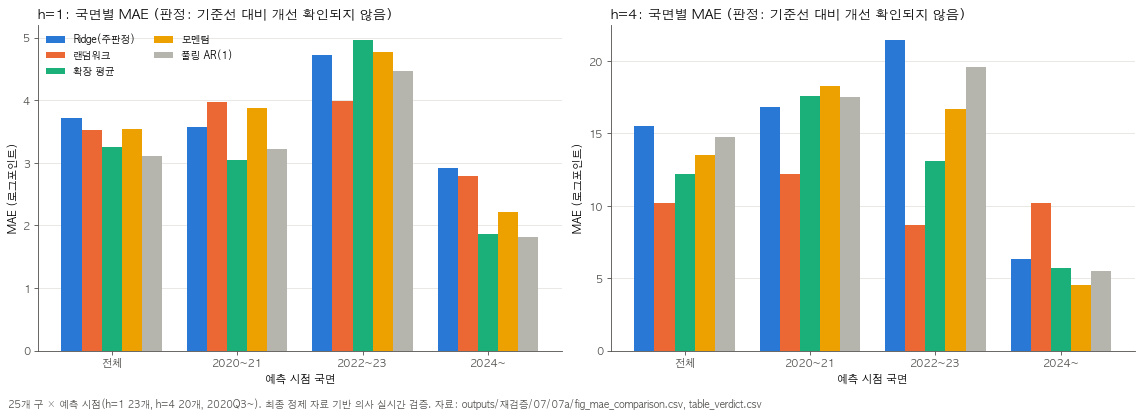

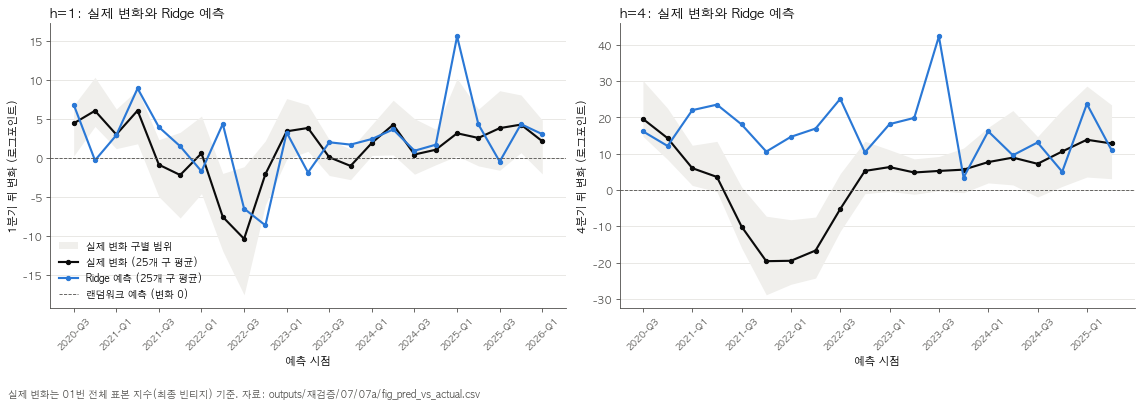

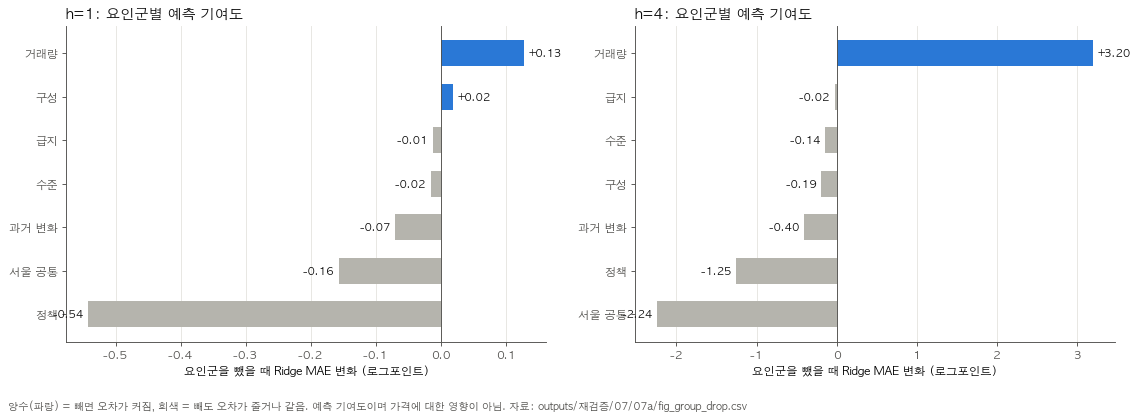

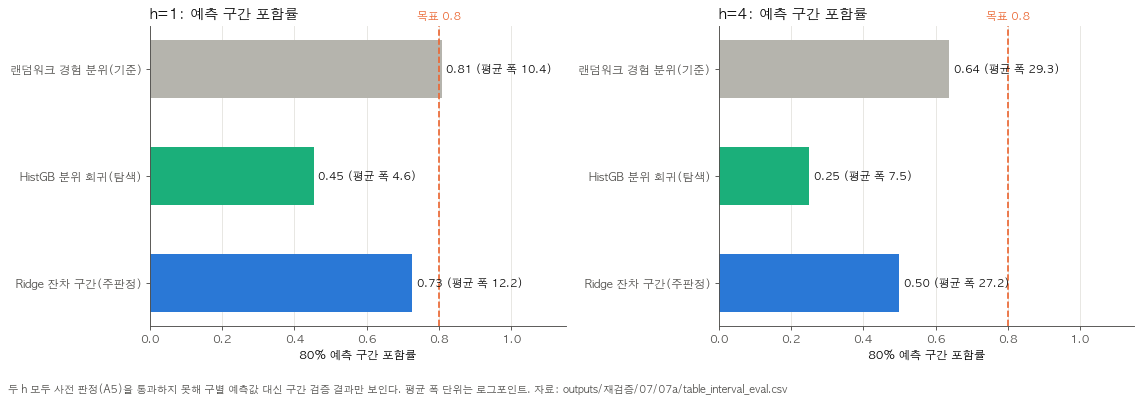

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # 범주 색 고정 순서
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"
MUTED = "#b5b4ad"


def style(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK2)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name):
    """폭 1200px 이하 PNG로 저장하고 노트북에 표시한다(이 노트북은 Agg 백엔드라 plt.show()로는 보이지 않음)."""
    from IPython.display import Image, display
    w = fig.get_size_inches()[0]
    fig.savefig(OUT / name, dpi=min(110, 1150 / w), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / name)))

OUT = ROOT / "outputs" / "재검증" / "07" / "07a"
verd = pd.read_csv(OUT / "table_verdict.csv")
PH = ["전체", "2020~21", "2022~23", "2024~"]
NAMES = ["Ridge(주판정)", "랜덤워크", "확장 평균", "모멘텀", "풀링 AR(1)"]
COLS = [SERIES[0], SERIES[1], SERIES[2], SERIES[3], MUTED]

# ① 국면별 MAE: Ridge vs 기준선
mae = pd.read_csv(OUT / "fig_mae_comparison.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, h in zip(axes, [1, 4]):
    d = mae[mae["h"] == h].pivot_table(index="phase", columns="model", values="mae").reindex(PH)
    wb = 0.16
    for i, (nm, c) in enumerate(zip(NAMES, COLS)):
        x = np.arange(len(PH)) + (i - 2) * wb
        ax.bar(x, d[nm], wb, color=c, label=nm)
    ax.set_xticks(np.arange(len(PH)), ["전체", "2020~21", "2022~23", "2024~"])
    v = verd[verd["h"] == h].iloc[0]
    ax.set_title(f"h={h}: 국면별 MAE (판정: {'기준선보다 나은 예측' if v['pass'] else '기준선 대비 개선 확인되지 않음'})",
                 loc="left", fontsize=12.5, color=INK)
    ax.set_xlabel("예측 시점 국면")
    ax.set_ylabel("MAE (로그포인트)")
    style(ax)
axes[0].legend(frameon=False, fontsize=9, ncol=2)
fig.text(0.01, -0.03, f"25개 구 × 예측 시점(h=1 {int(verd.loc[verd.h == 1, 'n_origin'].iloc[0])}개, h=4 {int(verd.loc[verd.h == 4, 'n_origin'].iloc[0])}개, 2020Q3~). "
         "최종 정제 자료 기반 의사 실시간 검증. 자료: outputs/재검증/07/07a/fig_mae_comparison.csv, table_verdict.csv", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_07a_1_mae_phase.png")

# ② 실제 vs 예측: 예측 시점별 25개 구 평균과 구별 범위
pv = pd.read_csv(OUT / "fig_pred_vs_actual.csv")
pv = pv[pv["eval_set"] == "주결과"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, h in zip(axes, [1, 4]):
    g = pv[pv["h"] == h].groupby("test_origin").agg(act=("actual", "mean"), lo=("actual", "min"), hi=("actual", "max"),
                                                    pred=("pred", "mean")).reset_index()
    x = np.arange(len(g))
    ax.fill_between(x, g["lo"], g["hi"], color=BAND, lw=0, label="실제 변화 구별 범위")
    ax.plot(x, g["act"], color=INK, lw=2, marker="o", ms=4, label="실제 변화 (25개 구 평균)")
    ax.plot(x, g["pred"], color=SERIES[0], lw=2, marker="o", ms=4, label="Ridge 예측 (25개 구 평균)")
    ax.axhline(0, color=INK2, lw=0.8, ls="--", label="랜덤워크 예측 (변화 0)")
    step = 2 if len(g) > 12 else 1
    ax.set_xticks(x[::step], g["test_origin"].iloc[::step], rotation=45, fontsize=8.5)
    ax.set_xlabel("예측 시점")
    ax.set_ylabel(f"{h}분기 뒤 변화 (로그포인트)")
    ax.set_title(f"h={h}: 실제 변화와 Ridge 예측", loc="left", fontsize=12.5, color=INK)
    style(ax)
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.text(0.01, -0.05, "실제 변화는 01번 전체 표본 지수(최종 빈티지) 기준. 자료: outputs/재검증/07/07a/fig_pred_vs_actual.csv", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_07a_2_actual_vs_pred.png")

# ③ 요인군 예측 기여도(요인군 제외 ΔMAE)
gd = pd.read_csv(OUT / "fig_group_drop.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, h in zip(axes, [1, 4]):
    d = gd[gd["h"] == h].sort_values("delta_mae")
    ax.barh(d["group"], d["delta_mae"], color=[SERIES[0] if v > 0 else MUTED for v in d["delta_mae"]], height=0.6)
    for i, v in enumerate(d["delta_mae"]):
        ax.annotate(f"{v:+.2f}", (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                    ha="left" if v >= 0 else "right", va="center", fontsize=9.5, color=INK)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlabel("요인군을 뺐을 때 Ridge MAE 변화 (로그포인트)")
    ax.set_title(f"h={h}: 요인군별 예측 기여도", loc="left", fontsize=12.5, color=INK)
    style(ax, grid="x")
fig.text(0.01, -0.05, "양수(파랑) = 빼면 오차가 커짐, 회색 = 빼도 오차가 줄거나 같음. 예측 기여도이며 가격에 대한 영향이 아님. "
         "자료: outputs/재검증/07/07a/fig_group_drop.csv", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_07a_3_group_contribution.png")

# ④ A5를 통과한 h가 있으면 그 h의 구별 예측 구간, 없으면 80% 구간 포함률
passed = verd.loc[verd["pass"].astype(bool), "h"].tolist()
if passed:
    fc = pd.read_csv(OUT / "fig_gu_forecast.csv")
    fig, axes = plt.subplots(1, len(passed), figsize=(7.5 * len(passed), 7), squeeze=False)
    for ax, h in zip(axes[0], passed):
        d = fc[(fc["h"] == h) & (fc["model_id"] == "ridge_resid")].sort_values("point")
        y = np.arange(len(d))
        ax.hlines(y, d["lo80"], d["hi80"], color=INK2, lw=1.4)
        ax.scatter(d["point"], y, color=SERIES[0], s=40, zorder=3)
        ax.set_yticks(y, d["gu"], fontsize=9)
        ax.axvline(0, color=INK2, lw=0.8)
        ax.set_xlabel(f"{h}분기 뒤 변화 모형 계산값 (로그포인트), 선은 80% 구간")
        ax.set_title(f"h={h}: 2026Q3 기준 구별 모형 계산값", loc="left", fontsize=12.5, color=INK)
        style(ax, grid="x")
    fig.text(0.01, -0.03, "2026Q3는 잠정 분기. 모형 계산값이며 매수·매도 판단 근거가 아님. 자료: outputs/재검증/07/07a/fig_gu_forecast.csv",
             fontsize=9, color=INK2)
    fig.tight_layout()
    save(fig, "viz_07a_4_forecast.png")
else:
    iv = pd.read_csv(OUT / "table_interval_eval.csv")
    lab = {"ridge_resid": "Ridge 잔차 구간(주판정)", "hgb_quantile": "HistGB 분위 회귀(탐색)", "rw_empirical": "랜덤워크 경험 분위(기준)"}
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    for ax, h in zip(axes, [1, 4]):
        d = iv[(iv["h"] == h) & iv["coverage80"].notna()].copy()
        d["lab"] = d["model_id"].map(lab)
        ax.barh(d["lab"], d["coverage80"], color=[SERIES[0], SERIES[2], MUTED], height=0.55)
        for i, (c, w) in enumerate(zip(d["coverage80"], d["mean_width"])):
            ax.annotate(f"{c:.2f} (평균 폭 {w:.1f})", (c, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9.5, color=INK)
        ax.axvline(0.8, color=SERIES[1], lw=1.5, ls="--")
        ax.text(0.8, 1.02, "목표 0.8", transform=ax.get_xaxis_transform(), ha="center", fontsize=9.5, color=SERIES[1])
        ax.set_xlim(0, 1.15)
        ax.set_xlabel("80% 예측 구간 포함률")
        ax.set_title(f"h={h}: 예측 구간 포함률", loc="left", fontsize=12.5, color=INK)
        style(ax, grid="x")
    fig.text(0.01, -0.05, "두 h 모두 사전 판정(A5)을 통과하지 못해 구별 예측값 대신 구간 검증 결과만 보인다. 평균 폭 단위는 로그포인트. "
             "자료: outputs/재검증/07/07a/table_interval_eval.csv", fontsize=9, color=INK2)
    fig.tight_layout()
    save(fig, "viz_07a_4_interval_coverage.png")